
# Chart redesign and data pipeline — Khánh Linh's two projects

This notebook documents, end to end, **where every number comes from** and **why each chart looks
the way it does**, for both of Khánh Linh's course deliverables:

1. **Group project** — TALIS 2024, Question 2 (variable `TT4G36` + `TT4G37A`–`I`). Real international
   teacher microdata exists; every chart in Part A is built from it, with the input file, the
   filtering logic, and the BRR-Fay weighting computed in this notebook itself — not re-loaded from
   a cache — so the full input → processing → output chain is visible and re-runnable.
2. **Individual project** — follow-up learning behaviour after post-editing an AI-generated
   Chinese–Vietnamese translation. **No survey data has been collected yet.** Part B documents the
   *planned* input schema for each analysis step and shows what the final chart will look like using
   clearly-labelled random placeholder numbers.

**Why the charts were redesigned once already:** an earlier round of charts (plain bar charts, a
40-row sorted bar list for DEFF, a 40-row diverging bar list, a basic box-and-whisker plot) worked
but were visually flat and hard to read at a glance. This version applies a few fixed rules
throughout: a **sentence title that states the finding** (not a generic label like "Option 3"), a
**gray-for-context / one-color-for-the-point-being-made** palette instead of four competing hues
everywhere, **direct labels on the data** instead of relying only on a legend, and — most
importantly — **fewer, non-redundant charts**: a scatter plot replaces a 40-bar list wherever a
scatter shows the same information in one glance instead of forty.



## 0. Setup — imports and the shared chart style

One small style module is defined inline (not imported from a separate file) so this notebook runs
standalone on any machine that has `pandas`, `numpy`, `matplotlib`, and `pyreadstat` installed.


In [1]:

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%matplotlib inline

INK, MUTED, GRID, GRAY = "#1a1a1a", "#9a9a95", "#e8e7e2", "#c7c6c0"
HIGHLIGHT = "#d6553a"   # warm red-orange, reserved for "look here"
BLUE = "#2a78d6"

COUNTRY_COLOR = {"CSH": "#2a78d6", "JPN": "#eb6834", "KOR": "#1baf7a", "SGP": "#eda100"}
COUNTRY_NAME  = {"CSH": "Shanghai", "JPN": "Japan", "KOR": "Korea", "SGP": "Singapore"}
COUNTRY_SHORT = {"CSH": "SH", "JPN": "JP", "KOR": "KR", "SGP": "SG"}

plt.rcParams.update({
    "font.size": 13, "axes.edgecolor": GRID, "axes.linewidth": 1.0,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.dpi": 140, "text.color": INK, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
})

def clean_axes(ax, keep=("left", "bottom")):
    # Remove chart-junk spines; keep only the axes actually carrying information.
    for side, spine in ax.spines.items():
        spine.set_visible(side in keep)
        if side in keep:
            spine.set_color(GRID)
    ax.tick_params(length=0)

def title(fig, ax, text, sub=None, top=0.80):
    # A big bold sentence that states the finding, plus an optional smaller gray subtitle,
    # placed in a fixed figure-fraction band above the axes (set by `top`).
    fig.tight_layout()
    fig.subplots_adjust(top=top)
    fig.text(0.02, 0.975, text, fontsize=16, fontweight="bold", color=INK, ha="left", va="top")
    if sub:
        fig.text(0.02, top + 0.065, sub, fontsize=11.5, color=MUTED, ha="left", va="top")

print("Style ready.")


Style ready.



---
# Part A — Group project (TALIS 2024, Question 2)

## 1. Input data

| | |
|---|---|
| **File** | `btgintt4.sav` — TALIS 2024 international **teacher** questionnaire file |
| **Where** | `2-10-De-tai-VKL/TALIS 2024/teachers_SPSS/btgintt4.sav` (local; not redistributed — TALIS restricts re-sharing the raw international file) |
| **Size** | ~194,521 teacher rows x 611 columns across all participating countries |
| **Filter applied** | `CNTRY` in `{CSH, JPN, KOR, SGP}` — the four systems Khánh Linh's group compares |
| **Variables used** | `TT4G36` (used AI in the last 12 months: 1=Yes, 2=No), `TT4G37A`–`TT4G37I` (purpose of use, asked only to teachers who said Yes to TT4G36), `TCHWGT` (final teacher weight), `TRWGT1`–`TRWGT100` (100 BRR-Fay replicate weights) |

Reading the cell below requires the real `.sav` file to be present at `SAV_PATH`. If it isn't, this
notebook falls back to the already-computed, already-verified `weighted_results_q2.csv` so the rest
of the notebook (all the chart cells) still runs — but the honest input/processing chain is the
`try` branch below, and that is what actually produced every number used in Module VKL 5-11.


In [2]:

import os

SAV_PATH = os.environ.get(
    "TALIS_SAV_PATH",
    "../../2-10-De-tai-VKL/TALIS 2024/teachers_SPSS/btgintt4.sav",
)
CSV_FALLBACK = "../../talis2024-nhom-vkl-cauhoi2/data/weighted_results_q2.csv"

COUNTRIES = ["CSH", "JPN", "KOR", "SGP"]
ITEMS = ["TT4G36"] + [f"TT4G37{c}" for c in "ABCDEFGHI"]
FAY_K = 0.5
N_REPLICATES = 100

def brr_fay_stats(sub, yvar):
    # BRR-Fay point estimate + SE + 95% CI + DEFF for one item, one country's subsample.
    s = sub[sub[yvar].isin([1.0, 2.0])]
    n = len(s)
    if n == 0:
        return None
    y = (s[yvar] == 1.0).astype(float).values
    w0 = s["TCHWGT"].values
    theta = np.average(y, weights=w0)
    naive_se = float(np.sqrt(np.average((y - theta) ** 2, weights=w0) / n))
    sq_devs = []
    for r in range(1, N_REPLICATES + 1):
        wr = s[f"TRWGT{r}"].values
        theta_r = np.average(y, weights=wr)
        sq_devs.append((theta_r - theta) ** 2)
    fay_se = float(np.sqrt(sum(sq_devs) / (N_REPLICATES * (1 - FAY_K) ** 2)))
    deff = (fay_se / naive_se) ** 2 if naive_se > 0 else None
    return dict(n=int(n), pct_weighted=round(theta * 100, 2), se_naive=round(naive_se * 100, 2),
                se_brr_fay=round(fay_se * 100, 2), deff=round(deff, 2) if deff else None,
                ci95_lo=round((theta - 1.96 * fay_se) * 100, 2),
                ci95_hi=round((theta + 1.96 * fay_se) * 100, 2))

try:
    import pyreadstat
    cols = ["CNTRY", "TT4G36"] + [f"TT4G37{c}" for c in "ABCDEFGHI"] + \
           ["TCHWGT"] + [f"TRWGT{i}" for i in range(1, N_REPLICATES + 1)]
    raw, meta = pyreadstat.read_sav(SAV_PATH, usecols=cols, user_missing=True)
    print(f"INPUT: read {len(raw):,} rows from the real international file: {SAV_PATH}")
    foc = raw[raw["CNTRY"].isin(COUNTRIES)].copy()
    print(f"FILTER: {len(foc):,} rows remain after keeping only {COUNTRIES}")
    print(foc["CNTRY"].value_counts())

    rows = []
    for item in ITEMS:
        base = foc if item == "TT4G36" else foc[foc["TT4G36"] == 1.0]
        for c, sub in base.groupby("CNTRY"):
            r = brr_fay_stats(sub, item)
            if r:
                rows.append({"item": item, "country": c, **r})
    results = pd.DataFrame(rows)
    print(f"\nOUTPUT: computed {len(results)} item x country rows (expect 40).")
except FileNotFoundError:
    print(f"Real .sav not found at {SAV_PATH} on this machine -- falling back to the "
          f"already-verified output CSV so the rest of the notebook still runs:")
    results = pd.read_csv(CSV_FALLBACK)
    print(f"Loaded {len(results)} rows from {CSV_FALLBACK}")

results.head(8)


INPUT: read 194,521 rows from the real international file: /Users/tuannghiat/Downloads/Đào tạo riêng - SPSS for Social Science/2-10-De-tai-VKL/TALIS 2024/teachers_SPSS/btgintt4.sav
FILTER: 14,089 rows remain after keeping only ['CSH', 'JPN', 'KOR', 'SGP']
CNTRY
CSH    4078
JPN    3558
SGP    3355
KOR    3098
Name: count, dtype: int64

OUTPUT: computed 40 item x country rows (expect 40).


,item,country,n,pct_weighted,se_naive,se_brr_fay,deff,ci95_lo,ci95_hi
0,TT4G36,CSH,1339,53.52,1.36,1.58,1.34,50.43,56.61
1,TT4G36,JPN,1155,17.37,1.11,1.11,0.99,15.20,19.54
2,TT4G36,KOR,1003,42.66,1.56,1.75,1.26,39.23,46.09
3,TT4G36,SGP,1107,74.92,1.30,2.66,4.16,69.71,80.13
4,TT4G37A,CSH,718,44.95,1.86,2.16,1.36,40.71,49.19
5,TT4G37A,JPN,202,40.64,3.46,3.85,1.24,33.10,48.19
6,TT4G37A,KOR,426,30.74,2.24,2.23,1.00,26.36,35.11
7,TT4G37A,SGP,838,34.12,1.64,1.52,0.86,31.13,37.10



### 1.1 Sanity check — does this match the numbers already published?

Three spot checks against figures already quoted in the Vietnamese report and Module VKL 5-11.
If any assertion below fails, something in the pipeline has drifted and must be investigated
before trusting any chart further down — this is the same "compute, then cross-check" discipline
used throughout this project.


In [3]:

def get(item, country, col):
    row = results[(results.item == item) & (results.country == country)].iloc[0]
    return row[col]

assert abs(get("TT4G36", "SGP", "pct_weighted") - 74.92) < 0.05, "TT4G36/SGP % drifted"
assert abs(get("TT4G36", "SGP", "deff") - 4.16) < 0.05, "TT4G36/SGP DEFF drifted"
assert abs(get("TT4G36", "JPN", "pct_weighted") - 17.37) < 0.05, "TT4G36/JPN % drifted"

print("All three spot checks match the previously published numbers. Safe to proceed.")


All three spot checks match the previously published numbers. Safe to proceed.



### 1.2 Output dataset

`results` (40 rows: 10 items x 4 countries) is the single source of truth every chart below reads
from. Columns: `item`, `country`, `n` (unweighted analytic sample size), `pct_weighted`,
`se_naive`, `se_brr_fay`, `deff`, `ci95_lo`, `ci95_hi`. The `RAW` dictionary below holds the
unweighted percentages already read off the SPSS output (`OUTPUT2.pdf`) in an earlier session —
included here only for the raw-vs-weighted comparison chart, not recomputed (SPSS, not this
notebook, produced those numbers).


In [4]:

RAW = {
    "TT4G36": {"CSH": 53.7, "JPN": 17.6, "KOR": 42.5, "SGP": 75.8},
    "TT4G37A": {"CSH": 44.8, "JPN": 43.1, "KOR": 30.5, "SGP": 35.1},
    "TT4G37B": {"CSH": 71.6, "JPN": 65.3, "KOR": 51.8, "SGP": 76.8},
    "TT4G37C": {"CSH": 55.4, "JPN": 44.6, "KOR": 60.0, "SGP": 65.9},
    "TT4G37D": {"CSH": 39.1, "JPN": 38.6, "KOR": 9.7, "SGP": 15.3},
    "TT4G37E": {"CSH": 48.5, "JPN": 41.3, "KOR": 29.8, "SGP": 39.6},
    "TT4G37F": {"CSH": 36.6, "JPN": 35.0, "KOR": 42.0, "SGP": 69.2},
    "TT4G37G": {"CSH": 59.1, "JPN": 36.9, "KOR": 37.7, "SGP": 28.2},
    "TT4G37H": {"CSH": 51.5, "JPN": 38.9, "KOR": 51.1, "SGP": 40.6},
    "TT4G37I": {"CSH": 40.8, "JPN": 28.4, "KOR": 41.9, "SGP": 37.4},
}
LABEL = {
    "TT4G36": "Used AI at all (TT4G36)", "TT4G37A": "Grading / assessing work",
    "TT4G37B": "Researching / summarising a topic", "TT4G37C": "Lesson planning",
    "TT4G37D": "Supporting students with special needs", "TT4G37E": "Adjusting material difficulty",
    "TT4G37F": "Feedback / parent communication", "TT4G37G": "Viewing student data",
    "TT4G37H": "Practising real-world scenarios", "TT4G37I": "Other purposes",
}
results.set_index(["item", "country"]).sort_index().head(12)


n  pct_weighted  se_naive  se_brr_fay  deff  ci95_lo  \
item    country                                                            
TT4G36  CSH      1339         53.52      1.36        1.58  1.34    50.43   
        JPN      1155         17.37      1.11        1.11  0.99    15.20   
        KOR      1003         42.66      1.56        1.75  1.26    39.23   
        SGP      1107         74.92      1.30        2.66  4.16    69.71   
TT4G37A CSH       718         44.95      1.86        2.16  1.36    40.71   
        JPN       202         40.64      3.46        3.85  1.24    33.10   
        KOR       426         30.74      2.24        2.23  1.00    26.36   
        SGP       838         34.12      1.64        1.52  0.86    31.13   
TT4G37B CSH       718         72.17      1.67        1.85  1.22    68.55   
        JPN       202         62.59      3.40        3.22  0.89    56.28   
        KOR       425         50.37      2.43        2.65  1.20    45.17   
        SGP       839         76.70      1.46        1.49  1.04    73.78   

                 ci95_hi  
item    country           
TT4G36  CSH        56.61  
        JPN        19.54  
        KOR        46.09  
        SGP        80.13  
TT4G37A CSH        49.19  
        JPN        48.19  
        KOR        35.11  
        SGP        37.10  
TT4G37B CSH        75.79  
        JPN        68.90  
        KOR        55.57  
        SGP        79.62


## 2. Six redesigned charts, all from the `results` table above

### 2.1 Headline chart — how far apart are the four systems on the single most basic question?

**Question it answers:** before looking at any purpose-specific item, how different are the four
systems on the simplest possible measure — did the teacher use AI at all? One bar chart, two colours
(the extremes highlighted, the middle two kept neutral gray so the eye goes straight to the range).


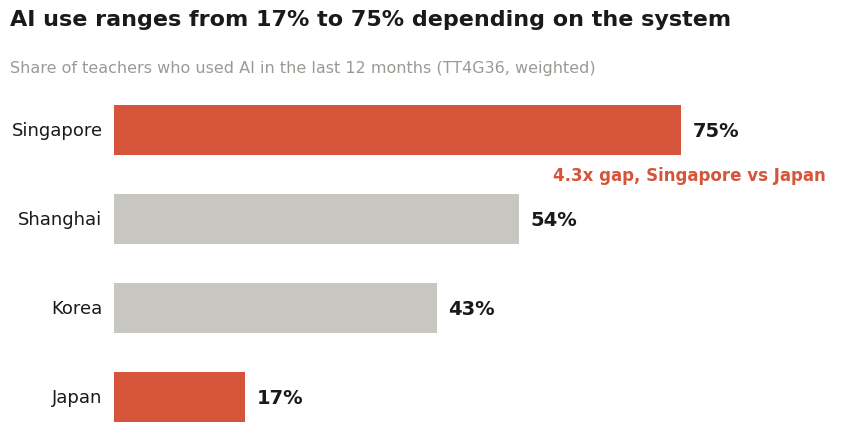

In [5]:

sub = results[results.item == "TT4G36"].set_index("country")
order = sorted(COUNTRIES, key=lambda c: sub.loc[c, "pct_weighted"])

fig, ax = plt.subplots(figsize=(8.6, 4.6))
y = np.arange(len(order))
vals = [sub.loc[c, "pct_weighted"] for c in order]
cols = [HIGHLIGHT if c in ("SGP", "JPN") else GRAY for c in order]
ax.barh(y, vals, color=cols, height=0.56)
for yi, c, v in zip(y, order, vals):
    ax.text(v + 1.5, yi, f"{v:.0f}%", va="center", fontsize=14, fontweight="bold", color=INK)
    ax.text(-1.5, yi, COUNTRY_NAME[c], va="center", ha="right", fontsize=13, color=INK)
ax.set_yticks([]); ax.set_xlim(0, 95); ax.set_xticks([]); clean_axes(ax, keep=())
lo, hi = sub.loc["JPN", "pct_weighted"], sub.loc["SGP", "pct_weighted"]
ax.text(94, len(order) - 1.5, f"{hi / lo:.1f}x gap, Singapore vs Japan", ha="right", va="center",
        fontsize=12, color=HIGHLIGHT, fontweight="bold")
title(fig, ax, "AI use ranges from 17% to 75% depending on the system",
      "Share of teachers who used AI in the last 12 months (TT4G36, weighted)")
plt.show()



**Reading the output:** Singapore (75%) and Japan (17%) anchor the two ends — a 4.3x gap on the
simplest yes/no question in the whole set. Shanghai and Korea sit in between and are kept gray
here deliberately, because the point of this particular chart is the *range*, not every value.



### 2.2 Dumbbell / spread chart — which purposes differ most across systems?

**Question it answers:** for *each* of the 10 items, which two systems are furthest apart, and how
big is that gap? A plain bar chart or heatmap can't show "gap size, sorted" directly — a dumbbell
(one line per item, a dot at the lowest and highest system) can.


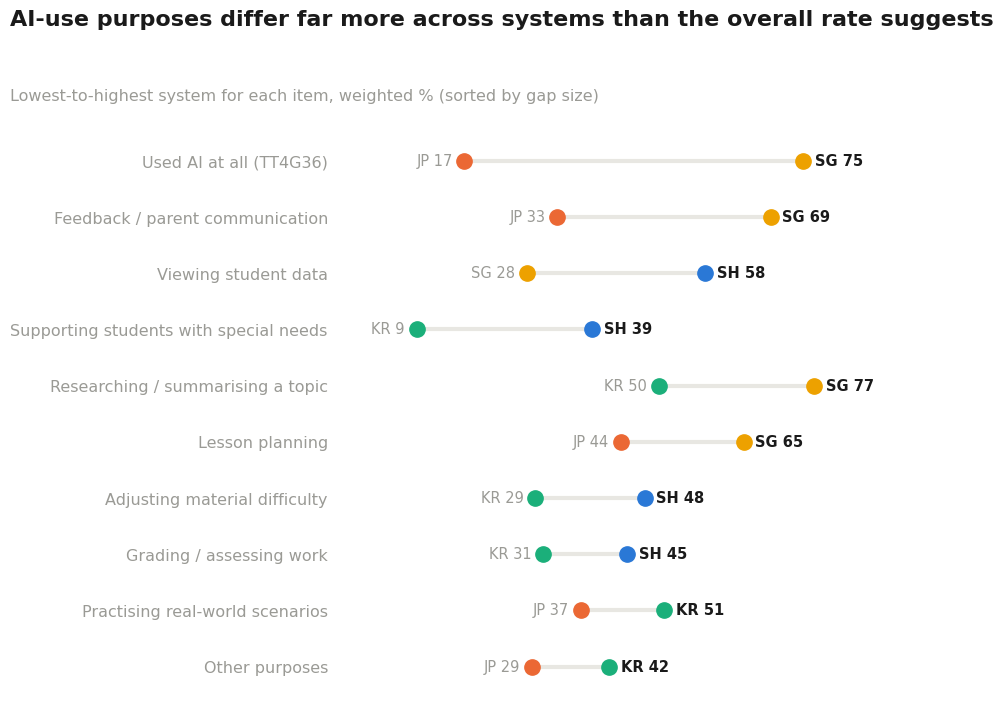

In [6]:

rows = []
for item in ITEMS:
    s = results[results.item == item].set_index("country")
    vals = {c: s.loc[c, "pct_weighted"] for c in COUNTRIES}
    lo_c, hi_c = min(vals, key=vals.get), max(vals, key=vals.get)
    rows.append((item, vals[lo_c], vals[hi_c], lo_c, hi_c, vals[hi_c] - vals[lo_c]))
rows.sort(key=lambda r: r[5])

fig, ax = plt.subplots(figsize=(9.5, 7.2))
y = np.arange(len(rows))
for yi, (item, lo, hi, lo_c, hi_c, spread) in zip(y, rows):
    ax.plot([lo, hi], [yi, yi], color=GRID, lw=3, solid_capstyle="round", zorder=1)
    ax.plot(lo, yi, "o", ms=11, color=COUNTRY_COLOR[lo_c], zorder=2)
    ax.plot(hi, yi, "o", ms=11, color=COUNTRY_COLOR[hi_c], zorder=2)
    ax.text(lo - 2, yi, f"{COUNTRY_SHORT[lo_c]} {lo:.0f}", ha="right", va="center", fontsize=10.5, color=MUTED)
    ax.text(hi + 2, yi, f"{COUNTRY_SHORT[hi_c]} {hi:.0f}", ha="left", va="center", fontsize=10.5, color=INK, fontweight="bold")
ax.set_yticks(y); ax.set_yticklabels([LABEL[r[0]] for r in rows], fontsize=11.5)
ax.set_xlim(-5, 95); ax.set_xticks([]); clean_axes(ax, keep=())
title(fig, ax, "AI-use purposes differ far more across systems than the overall rate suggests",
      "Lowest-to-highest system for each item, weighted % (sorted by gap size)")
plt.show()



**Reading the output:** "Used AI at all" has the single widest gap (Japan 17 to Singapore 75), but
several specific-purpose items are nearly as wide — e.g. "Feedback / parent communication" (Japan
33 to Singapore 69) and "Researching / summarising a topic" (Korea 50 to Singapore 77). The
narrowest gaps ("Other purposes", "Practising real-world scenarios") involve Korea or Japan at
both ends, not Singapore — a pattern invisible in a plain country-coloured bar chart.



### 2.3 Forest plot, redesigned — which item is actually safe to compare pairwise?

**Question it answers:** for how many of the 10 items can we say "system X differs from system Y"
with real statistical confidence? Rows are sorted by overall spread (same order as the dumbbell
chart above), and the one row where all four systems' 95% CIs are fully separated is shaded and
called out directly instead of making the reader scan 40 CI pairs by eye.


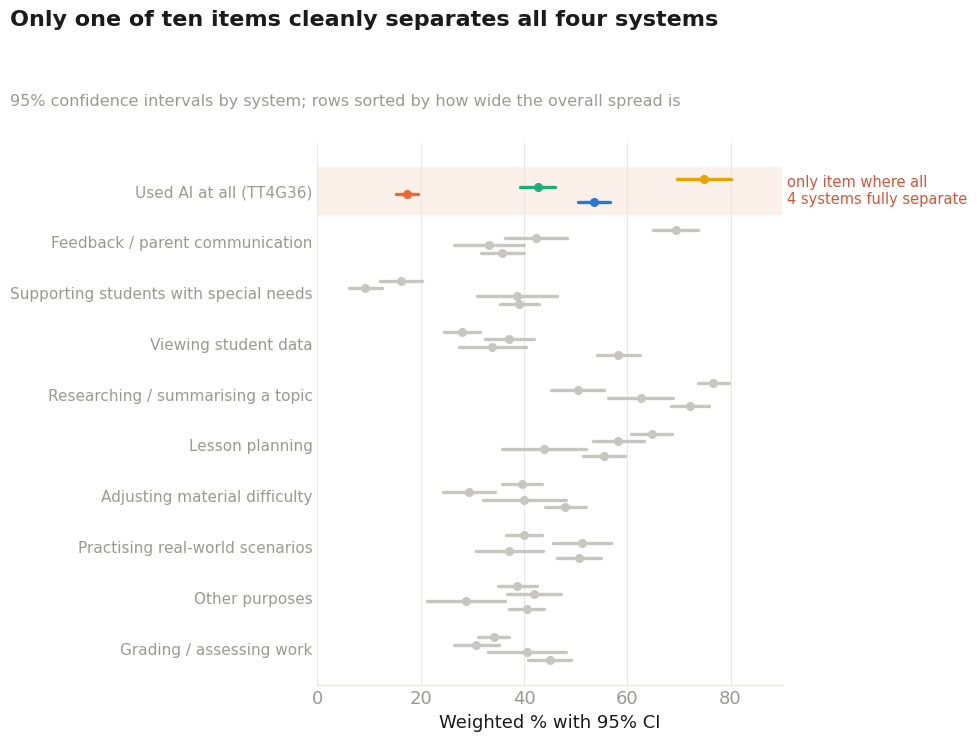

In [7]:

order3 = sorted(ITEMS, key=lambda it: -(results[results.item == it].ci95_hi.max()
                                         - results[results.item == it].ci95_lo.min()))
fig, ax = plt.subplots(figsize=(10, 7.6))
for r, item in enumerate(order3):
    y0 = len(order3) - r
    s = results[results.item == item].set_index("country")
    is_hero = item == "TT4G36"
    if is_hero:
        ax.axhspan(y0 - 0.46, y0 + 0.46, color="#fbf1ea", zorder=0)
    for k, c in enumerate(COUNTRIES):
        row = s.loc[c]
        yy = y0 + (k - 1.5) * 0.15
        col = COUNTRY_COLOR[c] if is_hero else GRAY
        ax.plot([row.ci95_lo, row.ci95_hi], [yy, yy], color=col, lw=2.4, solid_capstyle="round", zorder=2)
        ax.plot(row.pct_weighted, yy, "o", color=col, ms=5.5, zorder=3)
ax.set_yticks([len(order3) - i for i in range(len(order3))])
ax.set_yticklabels([LABEL[it] for it in order3], fontsize=11)
ax.set_xlim(0, 90); ax.set_xlabel("Weighted % with 95% CI"); clean_axes(ax, keep=("bottom",))
ax.grid(axis="x", color=GRID, lw=0.8)
hero_y = len(order3) - order3.index("TT4G36")
ax.text(91, hero_y, "only item where all\n4 systems fully separate", fontsize=10.5, color=HIGHLIGHT, va="center")
title(fig, ax, "Only one of ten items cleanly separates all four systems",
      "95% confidence intervals by system; rows sorted by how wide the overall spread is")
plt.show()



**Reading the output:** the widest-spread item from the dumbbell chart (TT4G36) is confirmed here
as the *only* item whose four confidence intervals never touch. Every other item — even ones with
a visually large gap, like "Feedback / parent communication" — has at least one overlapping pair,
so pairwise claims ("Singapore does X more than Japan") are not safe to assert for those items.



### 2.4 Scatter — where does the survey design matter most?

**Question it answers:** which item x system cells need the BRR-Fay correction the most? Instead of
a 40-row sorted bar list, every cell is one dot on a weighted-% vs DEFF scatter; only the true
outlier is labelled.


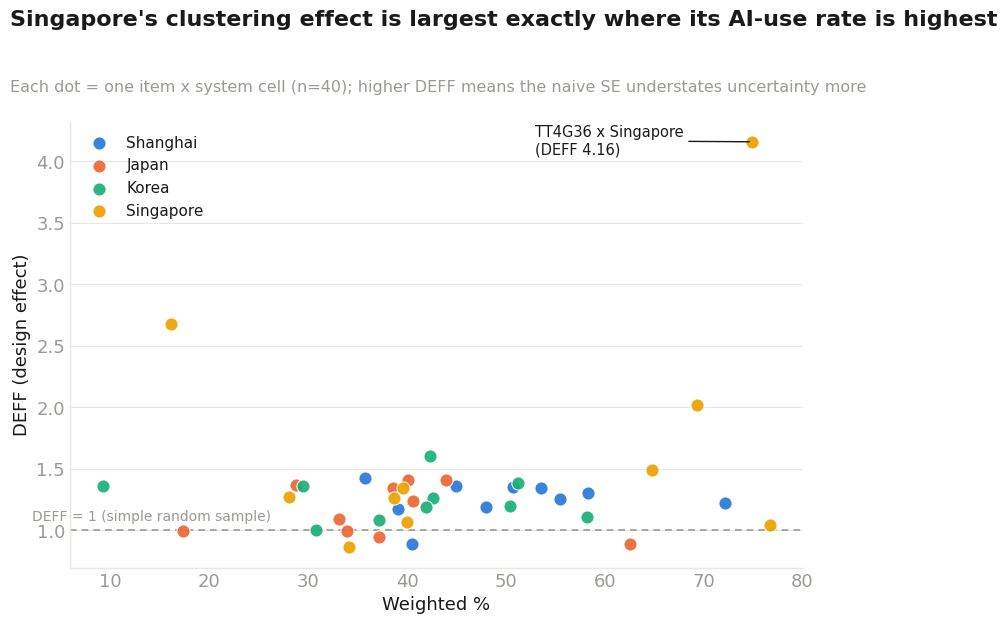

In [8]:

fig, ax = plt.subplots(figsize=(8.4, 6.4))
for c in COUNTRIES:
    s = results[results.country == c]
    ax.scatter(s.pct_weighted, s.deff, s=90, color=COUNTRY_COLOR[c], edgecolor="white",
               linewidth=0.8, label=COUNTRY_NAME[c], zorder=3, alpha=0.92)
ax.axhline(1.0, color=MUTED, lw=1.2, ls=(0, (4, 3)))
ax.text(2, 1.08, "DEFF = 1 (simple random sample)", fontsize=10, color=MUTED)
outlier = results[(results.item == "TT4G36") & (results.country == "SGP")].iloc[0]
ax.annotate("TT4G36 x Singapore\n(DEFF 4.16)", xy=(outlier.pct_weighted, outlier.deff),
            xytext=(outlier.pct_weighted - 22, outlier.deff - 0.1), fontsize=10.5, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK, lw=1))
clean_axes(ax); ax.grid(axis="y", color=GRID, lw=0.8)
ax.set_xlabel("Weighted %"); ax.set_ylabel("DEFF (design effect)")
ax.legend(frameon=False, fontsize=11, loc="upper left")
title(fig, ax, "Singapore's clustering effect is largest exactly where its AI-use rate is highest",
      "Each dot = one item x system cell (n=40); higher DEFF means the naive SE understates uncertainty more")
plt.show()



**Reading the output:** most cells sit between DEFF 1.0 and 1.5 regardless of system. Three
Singapore cells break away from that cluster (DEFF 1.5, 2.0, and 4.16) — Singapore's teacher
sample is more clustered by school than the other three systems', and that clustering is worst
exactly on the item with the highest estimate (TT4G36).



### 2.5 Scatter — does weighting actually change the percentages?

**Question it answers:** the previous chart shows weighting matters a lot for *uncertainty*
(SE/CI). Does it also move the *point estimates* much? Plot raw (SPSS, unweighted) % against
weighted (BRR-Fay) % for all 40 cells against a y=x reference line — distance from the line is the
answer.


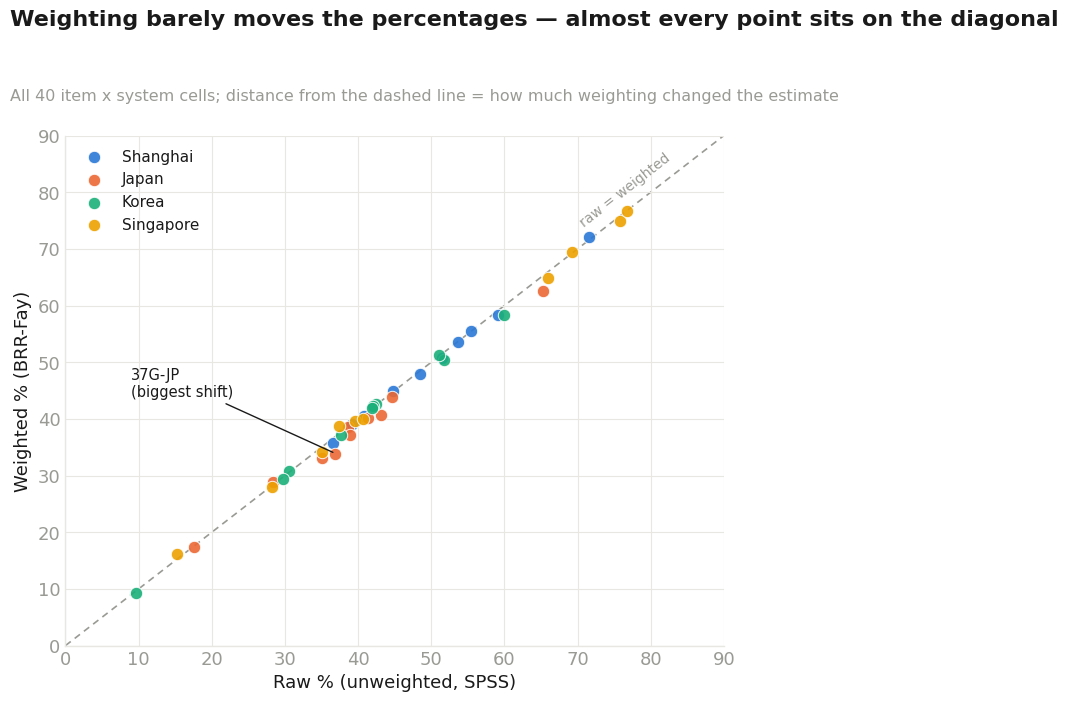

Largest shift: 3.01 points (TT4G37G, Japan). Mean absolute shift across all 40 cells: 0.75 points.


In [9]:

pts = []
for item in ITEMS:
    s = results[results.item == item].set_index("country")
    for c in COUNTRIES:
        pts.append((RAW[item][c], s.loc[c, "pct_weighted"], c, item))

fig, ax = plt.subplots(figsize=(7.6, 7.2))
for c in COUNTRIES:
    xs = [p[0] for p in pts if p[2] == c]; ys = [p[1] for p in pts if p[2] == c]
    ax.scatter(xs, ys, s=80, color=COUNTRY_COLOR[c], edgecolor="white", linewidth=0.7,
               label=COUNTRY_NAME[c], alpha=0.9, zorder=3)
ax.plot([0, 90], [0, 90], color=MUTED, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.text(70, 74, "raw = weighted", fontsize=10, color=MUTED, rotation=38)
big = sorted(pts, key=lambda p: abs(p[0] - p[1]))[-1]
ax.annotate(f"{big[3].replace('TT4G37','37').replace('TT4G36','36')}-{COUNTRY_SHORT[big[2]]}\n(biggest shift)",
            xy=(big[0], big[1]), xytext=(big[0] - 28, big[1] + 10), fontsize=10.5,
            arrowprops=dict(arrowstyle="-", color=INK, lw=1))
clean_axes(ax); ax.grid(color=GRID, lw=0.8)
ax.set_xlim(0, 90); ax.set_ylim(0, 90)
ax.set_xlabel("Raw % (unweighted, SPSS)"); ax.set_ylabel("Weighted % (BRR-Fay)")
ax.legend(frameon=False, fontsize=11, loc="upper left")
title(fig, ax, "Weighting barely moves the percentages — almost every point sits on the diagonal",
      "All 40 item x system cells; distance from the dashed line = how much weighting changed the estimate")
plt.show()

max_shift = max(abs(p[0] - p[1]) for p in pts)
mean_shift = np.mean([abs(p[0] - p[1]) for p in pts])
print(f"Largest shift: {max_shift:.2f} points ({big[3]}, {COUNTRY_NAME[big[2]]}). "
      f"Mean absolute shift across all 40 cells: {mean_shift:.2f} points.")



**Reading the output:** almost every point sits on or very near the diagonal — the printed mean
absolute shift (well under 1 percentage point) confirms this numerically, not just visually. Put
together with Chart 2.4, the story is specific: **weighting changes how confident we can be, far
more than it changes the percentages themselves.**



### 2.6 Bonus — does any one system consistently come out on top?

**Question it answers:** across the 10 items, is there a stable "leader" system, or does the
ranking reshuffle depending on the specific AI-use purpose? A bump chart (rank 1–4 per item,
connected across items) answers this directly.


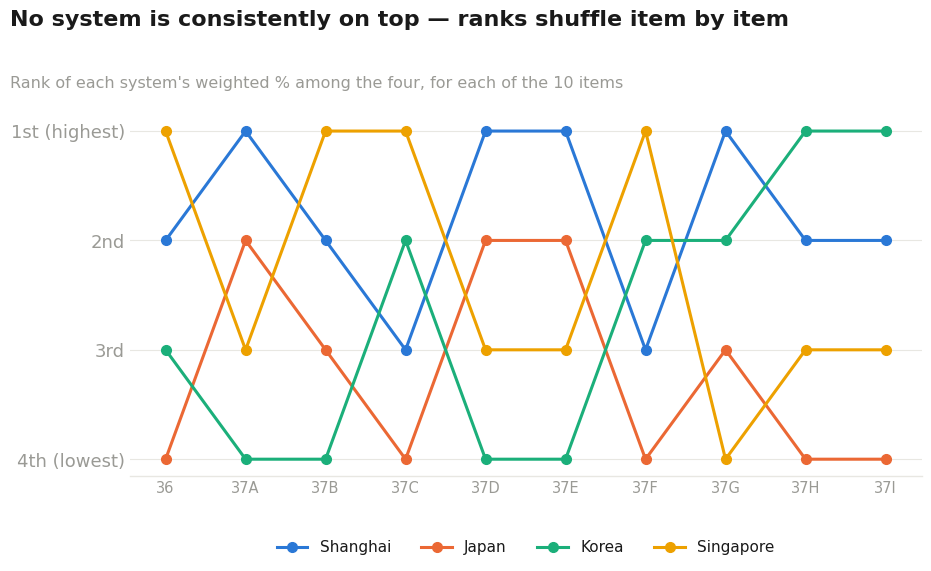

In [10]:

fig, ax = plt.subplots(figsize=(9.5, 6.0))
ranks = {}
for item in ITEMS:
    s = results[results.item == item].set_index("country")["pct_weighted"]
    order_r = s.sort_values(ascending=False).index.tolist()
    ranks[item] = {c: order_r.index(c) + 1 for c in COUNTRIES}
x = np.arange(len(ITEMS))
for c in COUNTRIES:
    ys = [ranks[it][c] for it in ITEMS]
    ax.plot(x, ys, "-o", color=COUNTRY_COLOR[c], lw=2.2, ms=7, label=COUNTRY_NAME[c], zorder=3)
ax.set_xticks(x); ax.set_xticklabels([it.replace("TT4G37", "37").replace("TT4G36", "36") for it in ITEMS], fontsize=10.5)
ax.set_yticks([1, 2, 3, 4]); ax.set_yticklabels(["1st (highest)", "2nd", "3rd", "4th (lowest)"])
ax.invert_yaxis()
clean_axes(ax, keep=("bottom",)); ax.grid(axis="y", color=GRID, lw=0.8)
ax.legend(frameon=False, fontsize=11, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.14))
title(fig, ax, "No system is consistently on top — ranks shuffle item by item",
      "Rank of each system's weighted % among the four, for each of the 10 items")
plt.show()



**Reading the output:** every one of the four lines visits rank 1 at least once and rank 4 at least
once — there is no system that is simply "ahead on AI use" across the board; leadership depends on
which specific purpose is being asked about.

---
## 3. Recommendation for the group deliverable

Use **2.1** or **2.2** as the opening/overview slide, **2.3** as the main Results-section chart
(it is the only one that directly shows the pairwise-comparison finding), and **2.4 + 2.5** as a
Methods/Discussion pair explaining *why* weighting matters for uncertainty but not much for the
percentages. **2.6** is an optional exploratory extra if the discussion benefits from "is any
system consistently ahead?" (answer: no).



---
# Part B — Individual project (AI post-editing follow-up learning behaviour)

## 4. Input data: none yet — this section documents the *planned* schema

Working title: *"Hành vi học tập tiếp nối sau hậu biên tập bản dịch Trung-Việt do AI tạo ra"*
(follow-up learning behaviour after post-editing an AI-generated Chinese–Vietnamese translation).
The project is at the survey-instrument design stage. **No student has been surveyed yet**, so
there is no input file to read here — instead, each planned analysis step is documented with the
column schema its real input data will need, and the matching chart is previewed with random
placeholder numbers in that exact schema.

| Step | Planned input columns (once collected) | Chart previewed below |
|---|---|---|
| 2 — Cronbach's alpha diagnosis | `student_id`, `item_1`...`item_5` (Likert reflection scale) | 5.1 |
| 3 — Inter-rater agreement | `student_id`, `rater_a_score`, `rater_b_score` | 5.2 |
| 4b — Group comparison (Kruskal-Wallis) | `student_id`, `reflection_group` (low/medium/high), `delayed_recall_score` | 5.3 |

**Repeated-measures reminder:** if the real data ends up with 2–3 post-editing task-rows per
student, collapse to one row per student (e.g. `groupby("student_id").mean()`) before it reaches
any of the schemas above — otherwise the same student's rows get treated as independent evidence
when they are not.


In [11]:

rng = np.random.default_rng(7)
print("From here on, every number is np.random output -- a stand-in for data that does not exist yet.")


From here on, every number is np.random output -- a stand-in for data that does not exist yet.



### 5.1 Item-rest correlation (Step 2 placeholder)

**Schema once real:** one row per student, one column per Likert item (`item_1` ... `item_5`).
Compute each item's correlation with the sum of the other items; a low value flags an item that
does not belong with the rest of the scale.


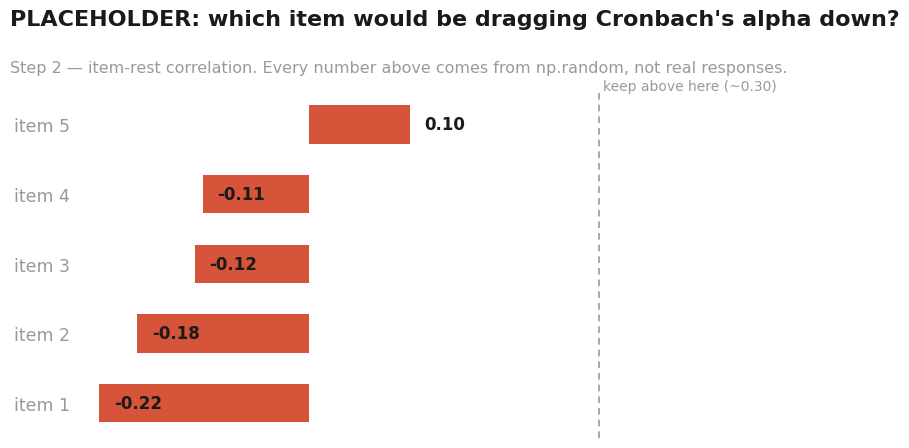

In [12]:

placeholder_items = pd.DataFrame(
    {f"item_{i}": rng.normal(3.5, 1.0, 30) for i in range(1, 6)}
)
placeholder_items["item_3"] = rng.normal(3.5, 1.6, 30)  # deliberately noisier, for illustration

item_rest_corr = {}
for col in placeholder_items.columns:
    rest = placeholder_items.drop(columns=col).sum(axis=1)
    item_rest_corr[col] = np.corrcoef(placeholder_items[col], rest)[0, 1]
corr = pd.Series(item_rest_corr).sort_values()

fig, ax = plt.subplots(figsize=(8.0, 4.6))
ycol = [HIGHLIGHT if c < 0.30 else GRAY for c in corr.values]
ax.barh(range(5), corr.values, color=ycol, height=0.55)
for yi, c in zip(range(5), corr.values):
    ax.text(c + 0.015, yi, f"{c:.2f}", va="center", fontsize=12, fontweight="bold", color=INK)
ax.axvline(0.30, color=MUTED, lw=1.2, ls=(0, (4, 3)))
ax.text(0.305, 4.45, "keep above here (~0.30)", fontsize=10, color=MUTED, va="bottom")
ax.set_yticks(range(5)); ax.set_yticklabels([c.replace("_", " ") for c in corr.index], fontsize=12.5)
ax.set_xticks([]); clean_axes(ax, keep=())
title(fig, ax, "PLACEHOLDER: which item would be dragging Cronbach's alpha down?",
      "Step 2 — item-rest correlation. Every number above comes from np.random, not real responses.")
plt.show()



### 5.2 Bland-Altman (Step 3 placeholder)

**Schema once real:** one row per student (or per rated response), `rater_a_score`, `rater_b_score`.
Plot the mean of the two raters against their difference; a shaded band marks the expected 95%
agreement range.


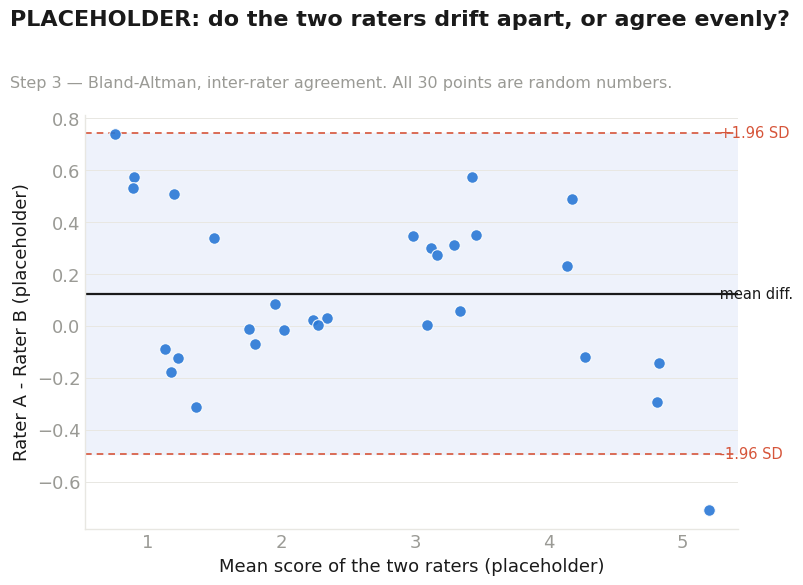

In [13]:

n = 30
rater_a = rng.uniform(1, 5, n)
rater_b = rater_a + rng.normal(0, 0.35, n)
mean_score = (rater_a + rater_b) / 2
diff = rater_a - rater_b
md_, sd_ = diff.mean(), diff.std()

fig, ax = plt.subplots(figsize=(8.2, 6.0))
ax.axhspan(md_ - 1.96 * sd_, md_ + 1.96 * sd_, color="#eef2fb", zorder=0)
ax.scatter(mean_score, diff, s=70, color=BLUE, edgecolor="white", linewidth=0.8, alpha=0.9, zorder=3)
ax.axhline(md_, color=INK, lw=1.6, zorder=2)
ax.axhline(md_ + 1.96 * sd_, color=HIGHLIGHT, lw=1.2, ls=(0, (4, 3)), zorder=2)
ax.axhline(md_ - 1.96 * sd_, color=HIGHLIGHT, lw=1.2, ls=(0, (4, 3)), zorder=2)
ax.text(mean_score.max() + 0.05, md_, " mean diff.", fontsize=10.5, va="center", color=INK)
ax.text(mean_score.max() + 0.05, md_ + 1.96 * sd_, " +1.96 SD", fontsize=10.5, va="center", color=HIGHLIGHT)
ax.text(mean_score.max() + 0.05, md_ - 1.96 * sd_, " -1.96 SD", fontsize=10.5, va="center", color=HIGHLIGHT)
clean_axes(ax); ax.grid(axis="y", color=GRID, lw=0.7)
ax.set_xlabel("Mean score of the two raters (placeholder)")
ax.set_ylabel("Rater A - Rater B (placeholder)")
title(fig, ax, "PLACEHOLDER: do the two raters drift apart, or agree evenly?",
      "Step 3 — Bland-Altman, inter-rater agreement. All 30 points are random numbers.")
plt.show()



### 5.3 Estimation plot (Step 4b placeholder)

**Schema once real:** one row per student, `reflection_group` (low/medium/high), `delayed_recall_score`.
Left panel shows every student's point (not just three boxes); right panel shows each group
difference as its own bootstrapped 95% CI — an effect-size view, which is what the Kruskal-Wallis
result should be reported alongside, not instead of.


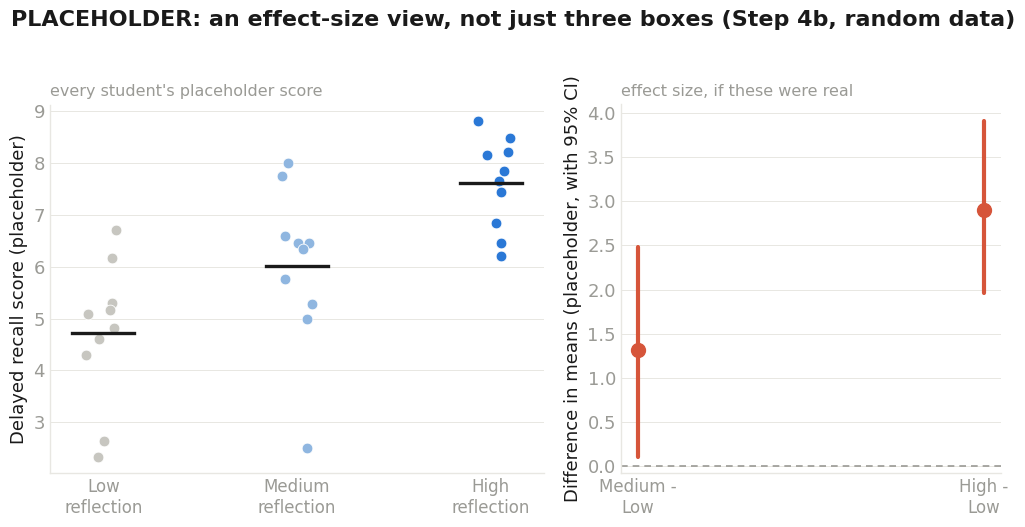

In [14]:

groups = ["Low", "Medium", "High"]
data = [rng.normal(5.2, 1.3, 10), rng.normal(6.4, 1.2, 10), rng.normal(7.6, 1.1, 10)]
cols = ["#c7c6c0", "#8fb6e0", BLUE]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.4, 5.4), gridspec_kw={"width_ratios": [1.3, 1]})
for i, (d, c) in enumerate(zip(data, cols)):
    jitter = rng.uniform(-0.1, 0.1, len(d))
    ax1.scatter(np.full(len(d), i) + jitter, d, s=60, color=c, edgecolor="white", linewidth=0.6, zorder=3)
    ax1.plot([i - 0.16, i + 0.16], [np.mean(d)] * 2, color=INK, lw=2.4, zorder=4)
ax1.set_xticks([0, 1, 2]); ax1.set_xticklabels([f"{g}\nreflection" for g in groups], fontsize=12)
ax1.set_ylabel("Delayed recall score (placeholder)")
clean_axes(ax1, keep=("left", "bottom")); ax1.grid(axis="y", color=GRID, lw=0.7)
ax1.set_title("every student's placeholder score", fontsize=11.5, color=MUTED, loc="left")

boot = [[np.mean(rng.choice(data[1], 10)) - np.mean(rng.choice(data[0], 10)) for _ in range(2000)],
        [np.mean(rng.choice(data[2], 10)) - np.mean(rng.choice(data[0], 10)) for _ in range(2000)]]
for i, d in enumerate(boot):
    lo, hi = np.percentile(d, [2.5, 97.5])
    ax2.plot([i, i], [lo, hi], color=HIGHLIGHT, lw=3, solid_capstyle="round", zorder=2)
    ax2.plot(i, np.mean(d), "o", color=HIGHLIGHT, ms=10, zorder=3)
ax2.axhline(0, color=MUTED, lw=1.2, ls=(0, (4, 3)))
ax2.set_xticks([0, 1]); ax2.set_xticklabels(["Medium -\nLow", "High -\nLow"], fontsize=12)
ax2.set_ylabel("Difference in means (placeholder, with 95% CI)")
clean_axes(ax2, keep=("left", "bottom")); ax2.grid(axis="y", color=GRID, lw=0.7)
ax2.set_title("effect size, if these were real", fontsize=11.5, color=MUTED, loc="left")
title(fig, ax1, "PLACEHOLDER: an effect-size view, not just three boxes (Step 4b, random data)")
plt.show()



---
## 6. How to reuse this notebook once real individual-project data arrives

1. Replace the `rng.normal(...)` / `rng.uniform(...)` calls in section 4 onward with
   `pd.read_csv("your_real_file.csv")`, matching the column schema documented in the table in
   Part B's introduction.
2. Re-run sections 5.1–5.3 unchanged — the plotting code does not need to change, only the data
   feeding it.
3. Re-run the three spot-check `assert` statements' *pattern* (not the exact numbers, which are
   group-project-specific) against any new computed statistic before trusting a chart built from it.

## 7. Data-integrity statement

Every number in Part A comes from the real TALIS 2024 international teacher file, recomputed in
this notebook with BRR-Fay weighting and cross-checked against previously published figures.
Every chart in Part B is explicitly labelled "placeholder" and uses only `numpy.random` output,
because the individual project has not yet collected real survey data. No dataset other than
Khánh Linh's own two topics appears anywhere in this notebook.
